In [1]:
import numpy as np
from numba import njit
import re 
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import os
import json
import h5py
import torch

In [2]:
class read_ising_file:

    def __init__(self, file):
        
        self.file = file
        # Leer archivo
        with open(file, 'r') as f:
            self.metadata = json.loads(f.readlines()[0][:-1])  

    def reshape_spin(self, index):
        """ Convertir un vector de espines plano a una matriz de espines tamaño LxL"""

        # Leer linea
        with open(self.file, 'r') as f:
            spin =  f.readlines()[index][:-1] 
        
        # Convertir a np.array
        arr = np.fromstring(spin, dtype=int, sep=',')
        arr = arr.reshape(self.metadata['L'], self.metadata['L'])
        return arr

    def plot_spin(self, spin_index=1, spin_arrows=True):
        """Graficar red de espines en B/N, con opción de flechas ↑ ↓ en cada celda"""
        spin = self.reshape_spin(spin_index)
        L = self.metadata["L"]

        plt.figure(figsize=(6, 6))
        plt.imshow(spin, cmap='gray', vmin=-1, vmax=1)

        plt.title(f'Red de espines T = {self.metadata["T"] :.3f}')
        plt.xlabel(f'Tamaño de la red: {L} x {L}')
        plt.ylabel('')

        if spin_arrows:
            # Dibuja las flechas
            for i in range(L):
                for self.metadata['J'] in range(L):
                    arrow = '↑' if spin[i, self.metadata['J']] == 1 else '↓'
                    color = 'black' if spin[i, self.metadata['J']] == 1 else 'white'
                    plt.text(
                        self.metadata['J'], i, arrow,
                        ha='center', va='center',
                        color=color, fontsize=14, fontweight='bold'
                    )

        plt.xticks([])
        plt.yticks([])
        plt.show()

    def magnetization(self, index):
        """Calcular magnetización de la red de espines"""
        spin = self.reshape_spin(index)
        return np.sum(spin)

    def load_all_spins(self, invert=True):
        """Cargar todos los espines del archivo de una vez (optimización I/O)"""
        all_spins = []

        with open(self.file, 'r') as f:
            lines = f.readlines()[1:]  # Saltar el header (metadata)
            for line in lines:
                if line.strip():  # Ignorar líneas vacías
                    arr = np.fromstring(line[:-1], dtype=int, sep=',')
                    arr = arr.reshape(self.metadata['L'], self.metadata['L'])
                    all_spins.append(arr)

                    # Agregar la red invertida
                    if invert: all_spins.append(-arr)
                    
        return all_spins
    
    def energy(self, index):
        """Calcular energía de la red de espines, con interacción entre primeros vecinos y campo magnético externo"""

        spin = self.reshape_spin(index)

        # Término de interacción entre primeros vecinos
        interaction_energy = 0.0
        
        # Interacciones horizontales (hacia la derecha)
        interaction_energy -= self.metadata['J'] * np.sum(spin[:, :-1] * spin[:, 1:])
        interaction_energy -= self.metadata['J'] * np.sum(spin[:, -1] * spin[:, 0])  # Condición periódica
        
        # Interacciones verticales (hacia abaself.metadata['J']o)
        interaction_energy -= self.metadata['J'] * np.sum(spin[:-1, :] * spin[1:, :])
        interaction_energy -= self.metadata['J'] * np.sum(spin[-1, :] * spin[0, :])  # Condición periódica
        
        # Término del campo magnético externo
        field_energy = -self.metadata['H'] * np.sum(spin)
        
        return interaction_energy + field_energy
    
    @staticmethod
    def calculate_energy(spin, metadata):
        """Calcular energía de un espín ya cargado (sin I/O)"""
        # Término de interacción entre primeros vecinos
        interaction_energy = 0.0
        
        # Interacciones horizontales (hacia la derecha)
        interaction_energy -= metadata['J'] * np.sum(spin[:, :-1] * spin[:, 1:])
        interaction_energy -= metadata['J'] * np.sum(spin[:, -1] * spin[:, 0])  # Condición periódica
        
        # Interacciones verticales (hacia abajo)
        interaction_energy -= metadata['J'] * np.sum(spin[:-1, :] * spin[1:, :])
        interaction_energy -= metadata['J'] * np.sum(spin[-1, :] * spin[0, :])  # Condición periódica
        
        # Término del campo magnético externo
        field_energy = -metadata['H'] * np.sum(spin)
        
        return interaction_energy + field_energy
    
    @staticmethod
    def calculate_magnetization(spin):
        """ Calcular magnetización de un espín ya cargado (sin I/O)"""
        return np.sum(spin)

    def invert_spins(spin):
        """ Invierte toda la red """
        return -spin

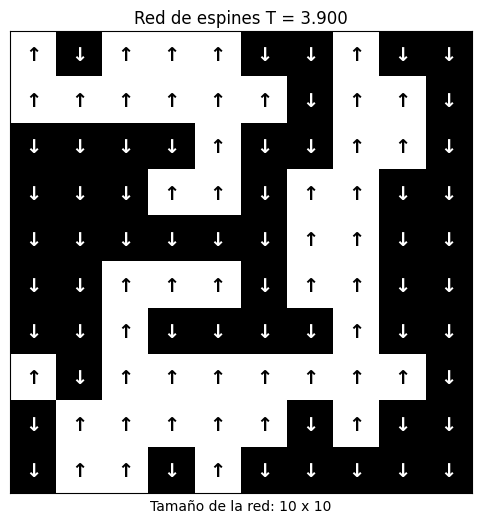

In [24]:
read_ising_file('./../data/ising_L10_T3.900_1.txt').plot_spin(103)

# Distribuciones

In [4]:
# Filtrar temperaturas desde objective_files y seleccionar archivos objetivo
temps = []
folder = './../data/'

T = ['0.700', '1.000', '1.700', '2.000', '2.300', '3.000', '3.500', '4.000'] # Temperaturas objetivo
patron = re.compile(r"_T([0-9.]+)_")  # Patrón para extraer temperaturas desde el filename


# Extraer archivos 
objective_files = []
for file in os.listdir(folder):
    match = patron.search(file)

    if match:
        # Extraer temperatura desde el filename
        temp_match = f"{float(match.group(1)):.3f}"
        temps.append(temp_match)

        # Agregar objective_files para temperaturas objetivo
        if temp_match in T and file not in objective_files:
            objective_files.append(file) 

## Energía

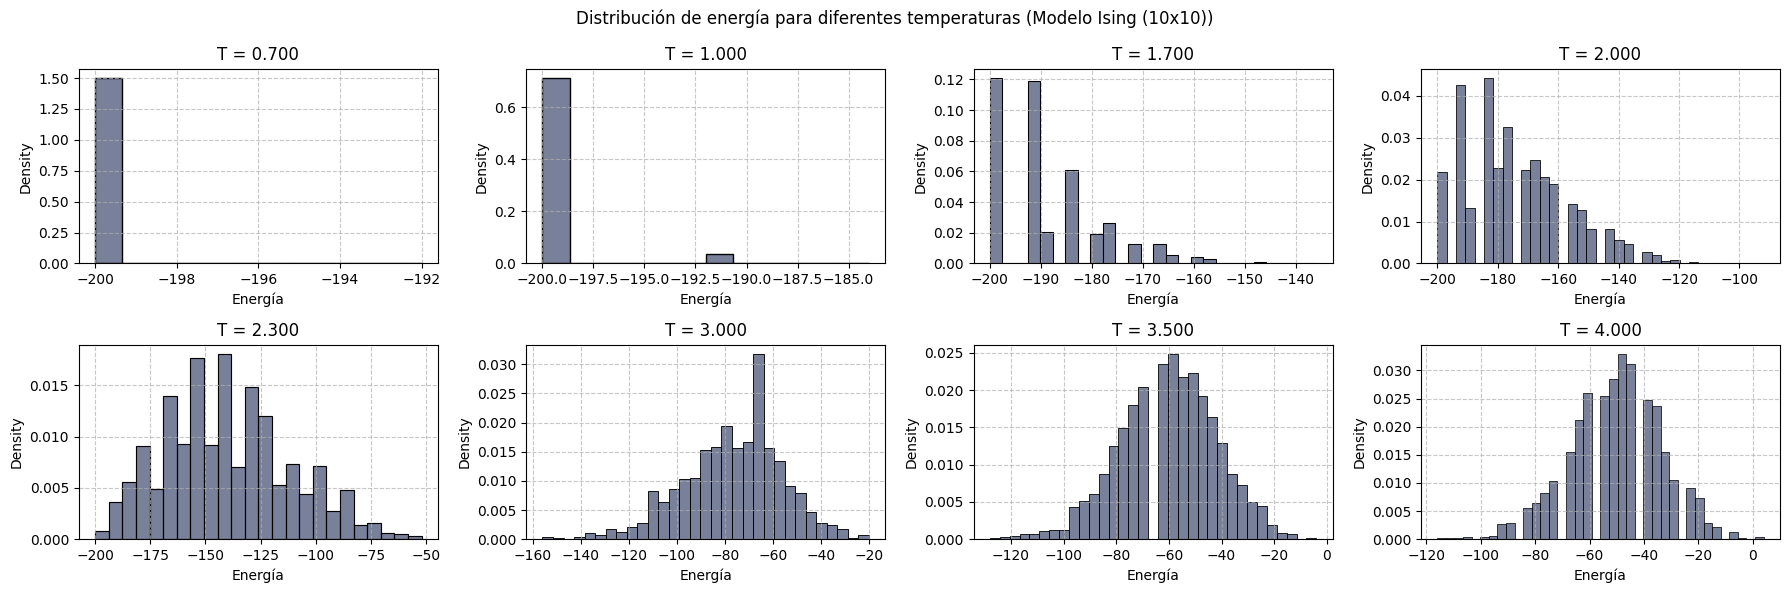

In [5]:

# Crear la figura y la grilla 
fig = plt.figure(figsize=(18, 6))
gs = gridspec.GridSpec(2, 4)

for i in range(8):
    ax = fig.add_subplot(gs[i])

    # Read file and calculate energy distribution (optimizado: carga todos los datos una vez)
    file = objective_files[i]
    ising = read_ising_file('./../data/' + file)
    all_spins = ising.load_all_spins(invert=False)  # Cargar todos los espines una vez
    energy = [read_ising_file.calculate_energy(spin, ising.metadata) for spin in all_spins]

    sns.histplot(energy, ax=ax, color="#3f4b6f", alpha=0.7, stat="density")
    ax.set_title(f"T = {T[i]}")
    ax.set_xlabel('Energía')
    ax.grid(True, linestyle="--", alpha=0.7)

fig.suptitle("Distribución de energía para diferentes temperaturas (Modelo Ising (10x10))")

plt.tight_layout()
plt.savefig('ising_energy_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


## Magnetización

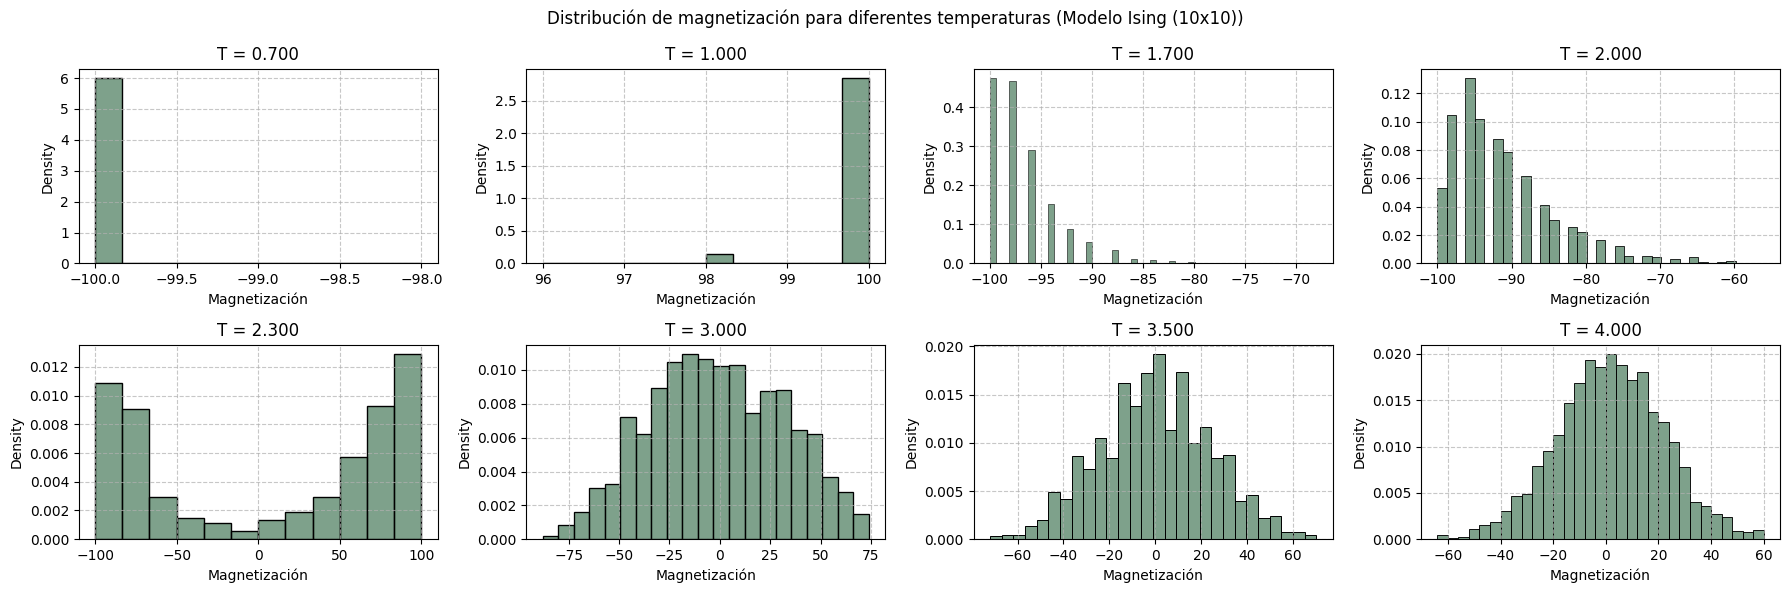

In [6]:

# Crear la figura y la grilla 
fig = plt.figure(figsize=(18, 6))
gs = gridspec.GridSpec(2, 4)

for i in range(8):
    ax = fig.add_subplot(gs[i])
    
    file = objective_files[i]
    ising = read_ising_file('./../data/' + file)
    all_spins = ising.load_all_spins(invert=False)  # Cargar todos los espines una vez
    magnetization = [read_ising_file.calculate_magnetization(spin) for spin in all_spins]

    sns.histplot(magnetization, ax=ax, color="#47795a", alpha=0.7, stat="density")
    ax.set_title(f"T = {T[i]}")
    ax.set_xlabel('Magnetización')
    ax.grid(True, linestyle="--", alpha=0.7)

fig.suptitle("Distribución de magnetización para diferentes temperaturas (Modelo Ising (10x10))")

plt.tight_layout()
plt.savefig('ising_magnetization_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


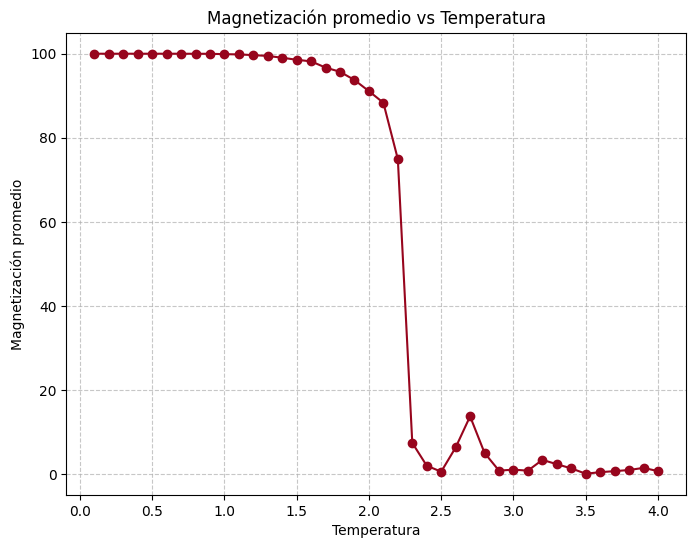

In [7]:
T = np.array(temps, dtype=float)
folder = './../data/'
M_mean = []

for file in os.listdir(folder):
    try:
        ising = read_ising_file(folder + file)
        all_spins = ising.load_all_spins(invert=False)  # Cargar todos los espines una vez
        magnetization = [read_ising_file.calculate_magnetization(spin) for spin in all_spins]
        M_mean.append(np.mean(magnetization))
    except (ValueError, KeyError, IndexError):
        # Ignorar archivos que no son válidos
        continue

M_mean = np.abs(np.array(M_mean))

plt.figure(figsize=(8, 6))
plt.plot(T, M_mean, marker='o', linestyle='-', color='#97051D')
plt.grid(True, linestyle="--", alpha=0.7)

plt.xlabel('Temperatura')
plt.ylabel('Magnetización promedio')
plt.title('Magnetización promedio vs Temperatura')
plt.savefig('isign_magnetization_vs_temperature.png', dpi=300, bbox_inches='tight')
plt.show()


# Lectura de datos

In [8]:
class ising_data_builder(read_ising_file):
    """Construye el dataset para entrenar los modelos, a partir de los datos generados en Ising_generator"""
    
    def __init__(self, folder, invert=True):
        self.folder = folder
        self.invert = invert

        self._scan_folder()
        self._build_dataset()
        # return self.h5_path

    def _scan_folder(self):
        # Escanear el folder con los archivos validos
        patron= re.compile(r"ising_")
        self.files = []

        for file in os.listdir(self.folder):
            match = patron.search(file)

            if match:
                self.files.append(file)
    
    def _load_file(self, file):
        super().__init__(file)

    def _build_dataset(self, h5_filename='dataset.h5'):
        #  Crear un file de tipo HDF5 para evitar uso excesivo de recurso usando recursión de lista
        # Guardar el h5
        h5_path = os.path.join(self.folder, h5_filename)
        if os.path.exists(h5_path):
            os.remove(h5_path)

        total = 0  
        f = h5py.File(h5_path, 'w')  
        dX = dy = None  # Inicializar datasets en None

        # Iterar sobre cada archivo de Ising encontrado en el folder
        for ising_file in self.files:
            self._load_file(self.folder + ising_file)
            X = np.asarray(self.load_all_spins())
            y = self.metadata['class'] * np.ones(len(X))

            # Si es la primera vez, crear los datasets dentro del archivo h5
            if dX is None:
                dX = f.create_dataset('X', data=X,
                                    maxshape=(None,) + X.shape[1:],
                                    chunks=True)
                dy = f.create_dataset('y', data=y,
                                    maxshape=(None,),
                                    chunks=True)
            else:
                # Si ya existen, hacer resize para agregar las nuevas muestras al final
                m = len(X)  
                dX.resize((total + m), axis=0)
                dy.resize((total + m), axis=0)
                dX[total: total + m] = X  # Escribir los nuevos datos de X
                dy[total: total + m] = y  # Escribir las nuevas etiquetas

            total += len(X)  

        f.close()  
        self.h5_path = h5_path  
        self.n_samples = total  

        return self.h5_path

# Crear el dataset
data = ising_data_builder('./../data/').h5_path


In [9]:
from torch.utils.data import Dataset

# Creamos una clase que sabe leer especificamente el dataset de Ising
class H5IsingDataset(Dataset):
    def __init__(self, h5_path):
        self.h5_path = h5_path
        self.file = h5py.File(self.h5_path, 'r')

        self.X = self.file['X']
        self.y = self.file['y']

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = torch.tensor(self.X[idx], dtype=torch.float32)
        y = torch.tensor(self.y[idx], dtype=torch.long)
        return x, y


from torch.utils.data import DataLoader

dataset = H5IsingDataset(data)

# loader = DataLoader(
#     dataset,
#     batch_size=64,
#     shuffle=True,
#     num_workers=0  
# )


In [10]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset, DataLoader

n = len(dataset)
labels = np.asarray(dataset.y[:]) 

# -- Train / Test Split estratificado --
train_idx, test_idx = train_test_split(
    np.arange(n),
    test_size=0.2,
    stratify=labels,
    random_state=4
)

# Subsets que no copian datos, solo crean vistas por índices
train_set = Subset(dataset, train_idx.tolist())
test_set  = Subset(dataset, test_idx.tolist())

# DataLoaders -> genera los batches
train_loader = DataLoader(train_set, batch_size=64, shuffle=True,  num_workers=0)
test_loader  = DataLoader(test_set,  batch_size=64, shuffle=False, num_workers=0)

# Dataset = un libro gigante.
# Subset = una lista de páginas específicas del libro.
# DataLoader = un ayudante que te pasa grupos de páginas (batches) mientras estudias.


# NN


In [11]:
import torch.nn as nn
from tqdm import tqdm

class IsingNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        # Topologia de la red 
        self.model = nn.Sequential(
            nn.Flatten(),          # <<< aplana el tensor a (batch, N)
            nn.Linear(input_dim, 100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.ReLU(),
            nn.Linear(100, 200),
            nn.ReLU(),
            nn.Linear(200, 100),
            nn.ReLU(),
            nn.Linear(100, 50),
            nn.ReLU(),
            nn.Linear(50, 1)
            # Nota: No aplicamos Sigmoid aquí porque BCEWithLogitsLoss lo hace internamente
            # de forma más estable numéricamente
        )

    def forward(self, x):
        return self.model(x)

# Model, loss, optimizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = IsingNN(input_dim=100).to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Entrenamiento
def train_epoch(model, loader):
    model.train()
    total_loss, total_correct, total = 0, 0, 0

    for X, y in loader:
        X, y = X.to(device), y.float().to(device)

        logits = model(X).squeeze()  # Forward y eliminar dimensión extra [batch, 1] -> [batch]
        loss = loss_fn(logits, y)    # Loss

        optimizer.zero_grad() # Limpiar gradientes
        loss.backward()       # Backward propagation
        optimizer.step()      # Update weights and biases

        total_loss += loss.item() * X.size(0) # Perdida del batch

        preds = (torch.sigmoid(logits) >= 0.5).long()     # Logits a labels
        total_correct += (preds == y.long()).sum().item() # Contar correctos
        total += X.size(0) 
        
    # Perdida promedio y accuracy
    return total_loss / total, total_correct / total 

# Desempeño
def eval_epoch(model, loader):
    model.eval()
    total_loss, total_correct, total = 0, 0, 0

    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.float().to(device)

            logits = model(X).squeeze()  # Eliminar dimensión extra [batch, 1] -> [batch]
            loss = loss_fn(logits, y)

            total_loss += loss.item() * X.size(0)
            preds = (torch.sigmoid(logits) >= 0.5).long()
            total_correct += (preds == y.long()).sum().item()
            total += X.size(0)

    return total_loss / total, total_correct / total

# Loop de entrenamiento
for epoch in tqdm(range(1, 6), desc="Epochs"):
    train_loss, train_acc = train_epoch(model, train_loader)
    test_loss, test_acc = eval_epoch(model, test_loader)

    print(f"Epoch {epoch} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
          f"Test Loss: {test_loss:.4f}, Acc: {test_acc:.4f}")

Epochs:  20%|██        | 1/5 [01:17<05:09, 77.26s/it]

Epoch 1 | Train Loss: 0.1207, Acc: 0.9523 | Test Loss: 0.1067, Acc: 0.9581


Epochs:  40%|████      | 2/5 [02:40<04:02, 80.99s/it]

Epoch 2 | Train Loss: 0.1037, Acc: 0.9587 | Test Loss: 0.0992, Acc: 0.9597


Epochs:  60%|██████    | 3/5 [04:18<02:57, 88.62s/it]

Epoch 3 | Train Loss: 0.0974, Acc: 0.9604 | Test Loss: 0.1011, Acc: 0.9593


Epochs:  80%|████████  | 4/5 [05:38<01:25, 85.32s/it]

Epoch 4 | Train Loss: 0.0923, Acc: 0.9618 | Test Loss: 0.0981, Acc: 0.9600


Epochs: 100%|██████████| 5/5 [07:03<00:00, 84.63s/it]

Epoch 5 | Train Loss: 0.0888, Acc: 0.9635 | Test Loss: 0.1063, Acc: 0.9597


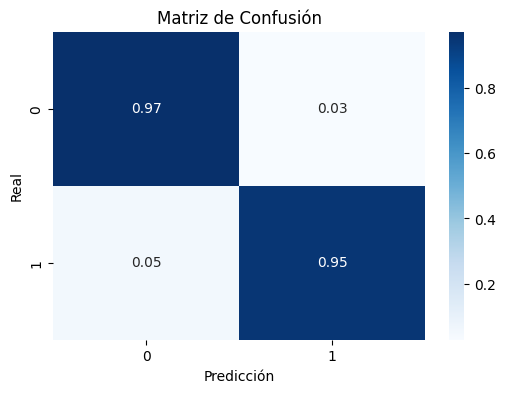

In [12]:
from sklearn.metrics import confusion_matrix

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for X, y in test_loader:
        X = X.float()

        logits = model(X)

        # Convertir a clases 0/1
        preds = (torch.sigmoid(logits) >= 0.5).long()

        # Guardar todo
        all_preds.append(preds.cpu())
        all_labels.append(y.long().cpu())

# Convertir listas de tensores a arrays numpy concatenados
all_preds = torch.cat(all_preds).numpy() 
all_labels = torch.cat(all_labels).numpy()

# Matriz de confusión
cm = confusion_matrix(all_labels, all_preds, normalize='true')

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión")
plt.show()

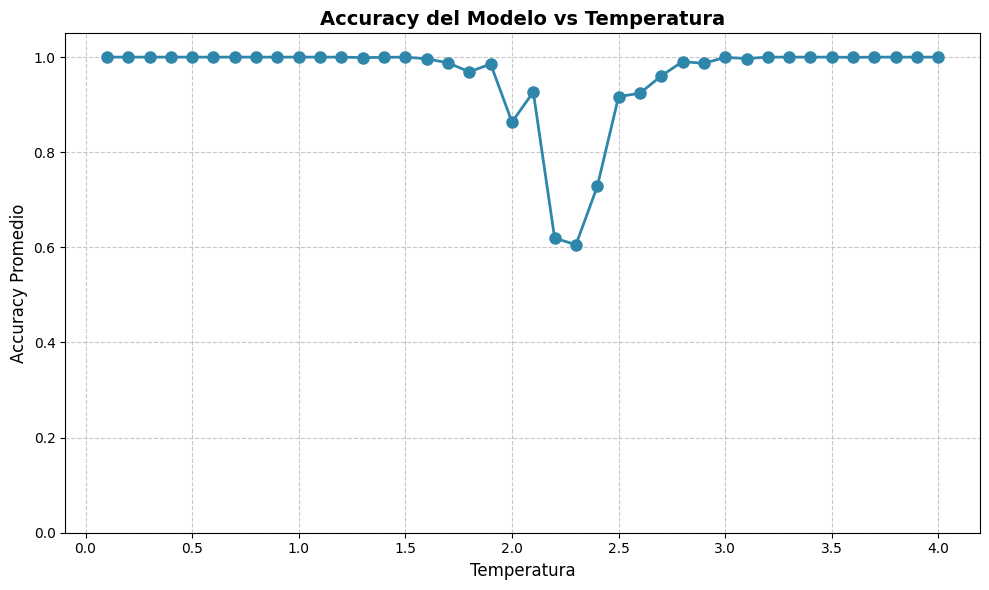

In [ ]:

# Análisis de accuracy por temperatura
from collections import defaultdict

model.eval()
temp_data = defaultdict(lambda: {'preds': [], 'labels': []})
folder = './../data/'

# Procesar archivos y hacer predicciones por lotes
for file in os.listdir(folder):
    if 'ising_' not in file:
        continue
    
    try:
        ising = read_ising_file(folder + file)
        temp = ising.metadata['T']
        label = ising.metadata['class']
        spins = ising.load_all_spins(invert=False)
        
        # Procesar todos los espines de un archivo en un solo batch
        with torch.no_grad():
            X = torch.tensor(spins, dtype=torch.float32).to(device)
            preds = (torch.sigmoid(model(X)) >= 0.5).long().cpu().numpy()
            
            temp_data[temp]['preds'].extend(preds)
            temp_data[temp]['labels'].extend([label] * len(preds))
    except (ValueError, KeyError, IndexError):
        continue

# Calcular accuracy por temperatura
temperaturas, accuracies = [], []
for temp in sorted(temp_data.keys()):
    preds = np.array(temp_data[temp]['preds'])
    labels = np.array(temp_data[temp]['labels'])
    accuracies.append(np.mean(preds == labels))
    temperaturas.append(temp)

temperaturas, accuracies = np.array(temperaturas), np.array(accuracies)

# Graficar
plt.figure(figsize=(10, 6))
plt.plot(temperaturas, accuracies, marker='o', linestyle='-', linewidth=2, markersize=8, color='#2E86AB')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlabel('Temperatura', fontsize=12)
plt.ylabel('Accuracy Promedio', fontsize=12)
plt.title('Accuracy del Modelo vs Temperatura', fontsize=14, fontweight='bold')
plt.ylim([0, 1.05])
plt.tight_layout()
plt.savefig('accuracy_vs_temperature.png', dpi=300, bbox_inches='tight')
plt.show()


# CNN 


In [14]:
# CNN con arquitectura AlexNet adaptada para 10x10
class AlexNetIsing(nn.Module):
    def __init__(self, num_classes=1):
        super().__init__()
        
        # Capas convolucionales (adaptadas para entrada 10x10)
        self.features = nn.Sequential(
            # Primera capa convolucional
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1),  # 10x10 -> 10x10
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 10x10 -> 5x5
            
            # Segunda capa convolucional
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),  # 5x5 -> 5x5
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 5x5 -> 2x2
            
            # Tercera capa convolucional
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),  # 2x2 -> 2x2
            nn.ReLU(inplace=True),
        )
        
        # Capas fully connected
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(128 * 2 * 2, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes)
        )
    
    def forward(self, x):
        # Asegurar que la entrada tenga la dimensión del canal
        if x.dim() == 3:  # (batch, height, width)
            x = x.unsqueeze(1)  # (batch, 1, height, width)
        
        x = self.features(x)
        x = x.view(x.size(0), -1)  # Flatten
        x = self.classifier(x)
        return x

# Model, loss, optimizer para CNN
model_cnn = AlexNetIsing(num_classes=1).to(device)
# Actualizar optimizer global para reutilizar las funciones train_epoch y eval_epoch existentes
optimizer = torch.optim.Adam(model_cnn.parameters(), lr=1e-3)

# Loop de entrenamiento (reutilizando train_epoch y eval_epoch de la celda anterior)
print("Entrenando CNN (AlexNet)...")
for epoch in tqdm(range(1, 6), desc="Epochs"):
    train_loss, train_acc = train_epoch(model_cnn, train_loader)
    test_loss, test_acc = eval_epoch(model_cnn, test_loader)

    print(f"Epoch {epoch} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
          f"Test Loss: {test_loss:.4f}, Acc: {test_acc:.4f}")


Entrenando CNN (AlexNet)...


Epochs:  20%|██        | 1/5 [01:39<06:36, 99.18s/it]

Epoch 1 | Train Loss: 0.1154, Acc: 0.9546 | Test Loss: 0.1099, Acc: 0.9577


Epochs:  40%|████      | 2/5 [03:25<05:10, 103.36s/it]

Epoch 2 | Train Loss: 0.1041, Acc: 0.9585 | Test Loss: 0.0971, Acc: 0.9591


...

Epoch 3 | Train Loss: 0.1017, Acc: 0.9597 | Test Loss: 0.0967, Acc: 0.9588


Epochs:  80%|████████  | 4/5 [07:06<01:47, 107.93s/it]

Epoch 4 | Train Loss: 0.0998, Acc: 0.9600 | Test Loss: 0.1045, Acc: 0.9574


Epochs: 100%|██████████| 5/5 [09:09<00:00, 109.88s/it]

Epoch 5 | Train Loss: 0.0980, Acc: 0.9602 | Test Loss: 0.0983, Acc: 0.9587


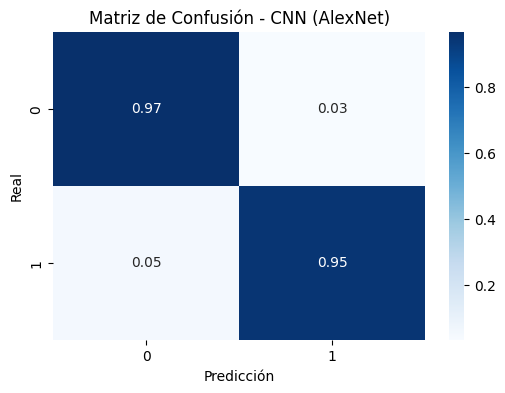

In [15]:
# Matriz de confusión para CNN
from sklearn.metrics import confusion_matrix

model_cnn.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)

        logits = model_cnn(X)

        # Convertir a clases 0/1
        preds = (torch.sigmoid(logits) >= 0.5).long()

        # Guardar todo
        all_preds.append(preds.cpu())
        all_labels.append(y.long().cpu())

# Convertir listas de tensores a arrays numpy concatenados
all_preds = torch.cat(all_preds).numpy() 
all_labels = torch.cat(all_labels).numpy()

# Matriz de confusión
cm = confusion_matrix(all_labels, all_preds, normalize='true')

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión - CNN (AlexNet)")
plt.show()


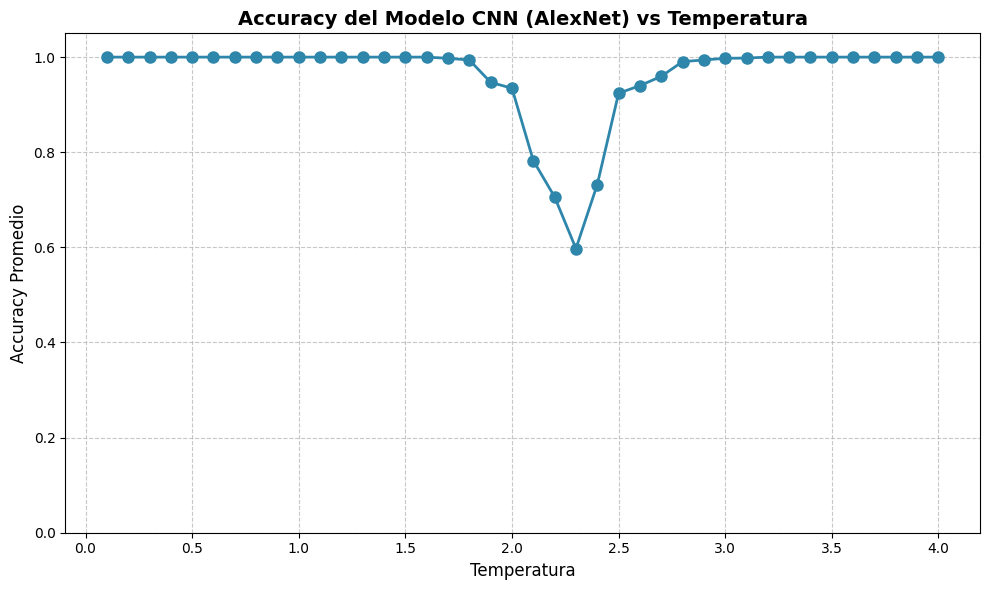


Accuracy por temperatura (CNN):
----------------------------------------
T = 0.100: 1.0000 (100.00%)
T = 0.200: 1.0000 (100.00%)
T = 0.300: 1.0000 (100.00%)
T = 0.400: 1.0000 (100.00%)
T = 0.500: 1.0000 (100.00%)
T = 0.600: 1.0000 (100.00%)
T = 0.700: 1.0000 (100.00%)
T = 0.800: 1.0000 (100.00%)
T = 0.900: 1.0000 (100.00%)
T = 1.000: 1.0000 (100.00%)
T = 1.100: 1.0000 (100.00%)
T = 1.200: 1.0000 (100.00%)
T = 1.300: 1.0000 (100.00%)
T = 1.400: 1.0000 (100.00%)
T = 1.500: 1.0000 (100.00%)
T = 1.600: 1.0000 (100.00%)
T = 1.700: 0.9975 (99.75%)
T = 1.800: 0.9940 (99.40%)
T = 1.900: 0.9470 (94.70%)
T = 2.000: 0.9345 (93.45%)
T = 2.100: 0.7825 (78.25%)
T = 2.200: 0.7060 (70.60%)
T = 2.300: 0.5975 (59.75%)
T = 2.400: 0.7320 (73.20%)
T = 2.500: 0.9240 (92.40%)
T = 2.600: 0.9400 (94.00%)
T = 2.700: 0.9595 (95.95%)
T = 2.800: 0.9905 (99.05%)
T = 2.900: 0.9940 (99.40%)
T = 3.000: 0.9975 (99.75%)
T = 3.100: 0.9980 (99.80%)
T = 3.200: 1.0000 (100.00%)
T = 3.300: 1.0000 (100.00%)
T = 3.400: 1.0000

In [16]:
# Accuracy por temperatura para CNN
from collections import defaultdict

model_cnn.eval()

# Diccionario para almacenar predicciones y etiquetas por temperatura
temp_data = defaultdict(lambda: {'preds': [], 'labels': []})

# Patrón para identificar archivos de Ising
patron = re.compile(r"ising_")

# Procesar cada archivo
folder = './../data/'
for file in os.listdir(folder):
    if not patron.search(file):
        continue
    
    try:
        # Cargar archivo y obtener metadata
        ising = read_ising_file(folder + file)
        temperatura = ising.metadata['T']
        etiqueta_real = ising.metadata['class']
        
        # Cargar todos los espines del archivo
        all_spins = ising.load_all_spins(invert=False)
        
        # Hacer predicciones para cada espín
        with torch.no_grad():
            for spin in all_spins:
                # Convertir espín a tensor
                X = torch.tensor(spin, dtype=torch.float32).unsqueeze(0).to(device)
                
                # Predicción del modelo
                logits = model_cnn(X)
                pred = (torch.sigmoid(logits) >= 0.5).long().cpu().item()
                
                # Guardar predicción y etiqueta real
                temp_data[temperatura]['preds'].append(pred)
                temp_data[temperatura]['labels'].append(etiqueta_real)
    
    except (ValueError, KeyError, IndexError) as e:
        # Ignorar archivos que no son válidos
        continue

# Calcular accuracy promedio por temperatura
temperaturas = []
accuracies = []

for temp in sorted(temp_data.keys()):
    preds = np.array(temp_data[temp]['preds'])
    labels = np.array(temp_data[temp]['labels'])
    
    # Calcular accuracy
    accuracy = np.mean(preds == labels)
    
    temperaturas.append(temp)
    accuracies.append(accuracy)

# Convertir a arrays numpy
temperaturas = np.array(temperaturas)
accuracies = np.array(accuracies)

# Graficar
plt.figure(figsize=(10, 6))
plt.plot(temperaturas, accuracies, marker='o', linestyle='-', linewidth=2, markersize=8, color='#2E86AB')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlabel('Temperatura', fontsize=12)
plt.ylabel('Accuracy Promedio', fontsize=12)
plt.title('Accuracy del Modelo CNN (AlexNet) vs Temperatura', fontsize=14, fontweight='bold')
plt.ylim([0, 1.05])
plt.tight_layout()
plt.savefig('accuracy_vs_temperature_cnn.png', dpi=300, bbox_inches='tight')
plt.show()


print("\nAccuracy por temperatura (CNN):")
print("-" * 40)
for temp, acc in zip(temperaturas, accuracies):
    print(f"T = {temp:.3f}: {acc:.4f} ({acc*100:.2f}%)")
